In [ ]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/kbbi_v.csv").drop_duplicates()
print(df.shape)

(146265, 16)


In [ ]:
# clustering: data hanya X (teks makna), tanpa label
umum = ["yang", "dan", "atau", "dengan", "untuk", "dalam", "tentang", "dapat", "ada", "sebagainya", "orang",
        "tidak", "di", "ke", "dari", "pada", "suatu", "hal"]
makna = df["submakna"].dropna()
sampel = makna[makna.str.split().str.len() >= 4].sample(3000, random_state=42)

vec = TfidfVectorizer(max_features=1500, min_df=3, stop_words=umum)
X = vec.fit_transform(sampel)

# ringkas fitur dengan SVD agar jarak antar data lebih bermakna
Z = make_pipeline(TruncatedSVD(50, random_state=42), Normalizer(copy=False)).fit_transform(X)
print(X.shape, Z.shape)

(3000, 1500) (3000, 50)


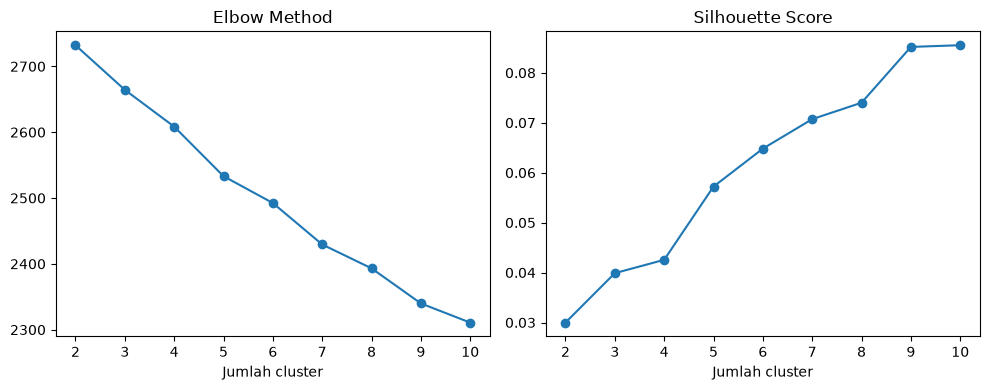

In [ ]:
# menentukan jumlah cluster: elbow method dan silhouette
k_range = range(2, 11)
inertia, sil = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(k_range, inertia, marker="o"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("Jumlah cluster")
ax[1].plot(k_range, sil, marker="o"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("Jumlah cluster")
plt.tight_layout()
plt.show()

In [ ]:
# latih model dengan jumlah cluster pilihan, lalu interpretasi
K = 6
model = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
hasil = pd.DataFrame({"makna": sampel.values, "cluster": model.labels_})
istilah = vec.get_feature_names_out()

print(f"Silhouette: {silhouette_score(Z, model.labels_, random_state=42):.3f}")
for i in range(K):
    pusat = np.asarray(X[model.labels_ == i].mean(axis=0)).ravel()
    contoh = hasil[hasil["cluster"] == i]["makna"].head(2).str[:50].tolist()
    print(f"Cluster {i} ({(model.labels_ == i).sum()} data):", ", ".join(istilah[pusat.argsort()[-6:][::-1]]))
    print("   contoh:", contoh)

Silhouette: 0.065
Cluster 0 (183 data): tempat, suku, bangsa, provinsi, daerah, mendiami
   contoh: ['meletakkan sajen di tempat-tempat keramat untuk me', 'merasa ngeri atau pusing (seperti ketika melihat k']
Cluster 1 (1490 data): bagian, alat, air, karena, tanah, seperti
   contoh: ['garis yang menjadi dasar segitiga', 'sebodoh bodohnya orang, jika berusaha dan belajar ']
Cluster 2 (594 data): oleh, secara, sama, tertentu, nama, kegiatan
   contoh: ['keputusan yang diperoleh berdasarkan metode berpik', 'tempat berkumpul untuk membaca atau melakukan kegi']
Cluster 3 (96 data): perbuatan, cara, proses, jahat, kelakuan, pandangan
   contoh: ['siapa yang bersalah harus dihukum; perbuatan jahat', 'proses, cara, perbuatan meluaskan atau memperluas']
Cluster 4 (475 data): digunakan, bahan, berwarna, biasanya, dibuat, panjang
   contoh: ['calir yang digunakan untuk membersihkan wajah, dap', 'musang yang bentuknya mirip berang-berang, termasu']
Cluster 5 (162 data): sesuatu, kepada, segala, m

In [ ]:
# evaluasi tambahan: bandingkan cluster dengan kelas kata (label tidak dipakai saat melatih)
kelas = df.loc[sampel.index, "kelas"].str.split(";").str[0].str.strip()
pd.crosstab(hasil["cluster"].values, kelas.values).loc[:, lambda t: t.sum() > 50]

col_0,Adjektiva,Nomina,Verba
row_0,,,
0,8,113,12
1,118,598,295
2,39,263,45
3,0,76,3
4,19,254,42
5,15,71,34


In [ ]:
# association: atribut apa yang sering muncul bersamaan dalam satu entri kata
atribut = ["kata_turunan", "gabungan_kata", "peribahasa", "idiom", "contoh", "etimologi", "varian"]
T = df[atribut].notna()
n = len(T)

aturan = []
for a, b in itertools.permutations(atribut, 2):
    both = (T[a] & T[b]).sum()
    if both == 0:
        continue
    support = both / n
    confidence = both / T[a].sum()
    lift = confidence / (T[b].sum() / n)
    aturan.append((f"{a} -> {b}", support, confidence, lift))

aturan = pd.DataFrame(aturan, columns=["aturan", "support", "confidence", "lift"])
aturan.sort_values("lift", ascending=False).head(8).round(3)

,aturan,support,confidence,lift
20,idiom -> peribahasa,0.006,0.783,22.978
14,peribahasa -> idiom,0.006,0.188,22.978
19,idiom -> gabungan_kata,0.005,0.616,6.643
8,gabungan_kata -> idiom,0.005,0.054,6.643
13,peribahasa -> gabungan_kata,0.016,0.480,5.176
7,gabungan_kata -> peribahasa,0.016,0.176,5.176
2,kata_turunan -> idiom,0.005,0.041,4.981
18,idiom -> kata_turunan,0.005,0.584,4.981


In [ ]:
# aturan yang kuat: confidence tinggi dan lift di atas 1
aturan[(aturan["confidence"] > 0.3) & (aturan["lift"] > 1)].sort_values("lift", ascending=False).round(3)

,aturan,support,confidence,lift
20,idiom -> peribahasa,0.006,0.783,22.978
19,idiom -> gabungan_kata,0.005,0.616,6.643
13,peribahasa -> gabungan_kata,0.016,0.480,5.176
18,idiom -> kata_turunan,0.005,0.584,4.981
6,gabungan_kata -> kata_turunan,0.045,0.480,4.094
0,kata_turunan -> gabungan_kata,0.045,0.380,4.094
30,etimologi -> kata_turunan,0.024,0.474,4.047
12,peribahasa -> kata_turunan,0.016,0.463,3.953
40,varian -> contoh,0.002,0.673,3.408
21,idiom -> contoh,0.005,0.658,3.332


In [ ]:
# refleksi: supervised atau unsupervised?
pd.DataFrame({
    "Skenario": [1, 2, 3, 4, 5],
    "Tipe": ["Supervised", "Unsupervised", "Supervised", "Unsupervised", "Unsupervised"],
    "Jenis": ["Klasifikasi", "Clustering", "Regresi", "Clustering", "Association"],
    "Alasan": ["Label gagal bayar tersedia", "Grup pengguna tidak punya label", "Label berupa angka (harga)",
               "Topik tidak diberi label manual", "Mencari produk yang dibeli bersamaan"],
})

,Skenario,Tipe,Jenis,Alasan
0,1,Supervised,Klasifikasi,Label gagal bayar tersedia
1,2,Unsupervised,Clustering,Grup pengguna tidak punya label
2,3,Supervised,Regresi,Label berupa angka (harga)
3,4,Unsupervised,Clustering,Topik tidak diberi label manual
4,5,Unsupervised,Association,Mencari produk yang dibeli bersamaan


## Analisis

Pada clustering, grafik elbow tidak memperlihatkan siku yang jelas karena inertia turun landai dari 2.732,6 (K=2) ke 2.317,9 (K=10). Silhouette score naik terus dari 0,029 sampai 0,083 pada K=10, tetapi semua nilainya masih di bawah 0,1, yang berarti cluster saling tumpang tindih dan batasnya tidak tegas. Dengan K=6, silhouette-nya 0,058. Ukuran cluster sangat timpang: cluster 1 paling besar (1.466 dari 3.000 data) dengan kata umum seperti tempat, alat, dan air, sedangkan cluster 4 hanya 95 data yang bercirikan perbuatan, cara, dan proses. Bila dibandingkan dengan kelas kata, nomina dominan di semua cluster (misalnya 75 dari 79 data berlabel di cluster 4), sehingga cluster ini terbentuk dari pola kata dalam makna, bukan dari kelas kata.

Pada association, pasangan atribut yang paling kuat adalah idiom dan peribahasa. Dari entri yang punya idiom, 78,3 persen juga punya peribahasa, dan kemunculan bersamanya 23 kali lebih sering daripada kebetulan (lift 22,98). Pasangan gabungan_kata dan kata_turunan juga saling terkait (lift 4,09) dengan support terbesar (4,5 persen data). Nilai support yang kecil pada aturan idiom menunjukkan atribut ini jarang muncul, jadi aturannya kuat tetapi hanya berlaku pada sebagian kecil entri.